## 1. Fonte dos dados

Este projeto utiliza os dados anonimizados disponibilizados por **Denning et al. (2021)** no artigo *Determinants of burnout and other aspects of psychological well-being in healthcare workers during the Covid-19 pandemic: A multinational cross-sectional study*, publicado na revista *PLOS ONE*.

Trata-se de um **estudo observacional transversal**, realizado durante a pandemia de COVID-19, com profissionais de serviços de saúde do **Reino Unido, Polônia e Singapura**. O objetivo do estudo original foi investigar a ocorrência de burnout, ansiedade e depressão entre os participantes e examinar fatores demográficos, profissionais e organizacionais associados a esses desfechos.

A pesquisa reuniu informações demográficas e profissionais e utilizou três instrumentos:

- **Safety Attitudes Questionnaire (SAQ):** avalia percepções sobre trabalho em equipe, segurança, satisfação profissional, gestão e condições organizacionais.
- **Oldenburg Burnout Inventory (OLBI):** avalia burnout por meio das dimensões de exaustão e distanciamento em relação ao trabalho.
- **Hospital Anxiety and Depression Scale (HADS):** avalia sintomas de ansiedade e depressão.

Neste TCC, os dados serão examinados para desenvolver e avaliar **modelos preditivos de aprendizado de máquina**, por meio de **classificação supervisionada de burnout elevado**, utilizando a classificação original de `Burnout?`: 3 corresponde à classe positiva e 0, 1 e 2 à negativa, conforme definido na seção 5.1. Posteriormente, técnicas de Inteligência Artificial Explicável (XAI) poderão ser utilizadas para interpretar as previsões e examinar a contribuição dos atributos.

Como a pesquisa é transversal, as previsões se referem à **classificação da condição observada no momento da coleta**, e não à previsão de surgimento futuro de burnout. Essa classificação não equivale, por si só, a um diagnóstico clínico.

**Fontes oficiais:**

- **Artigo científico:** [Denning et al. (2021)](https://doi.org/10.1371/journal.pone.0238666).
- **S1 File:** [questionários e regras de pontuação do SAQ](https://doi.org/10.1371/journal.pone.0238666.s001).
- **S2 File:** [base de dados anonimizada (CSV)](https://doi.org/10.1371/journal.pone.0238666.s002).

**Referência:** DENNING, M. et al. Determinants of burnout and other aspects of psychological well-being in healthcare workers during the Covid-19 pandemic: A multinational cross-sectional study. *PLOS ONE*, v. 16, n. 4, e0238666, 2021. DOI: [10.1371/journal.pone.0238666](https://doi.org/10.1371/journal.pone.0238666).

## 2. Metadados

O arquivo suplementar S2 contém **3.537 registros e 180 colunas com conteúdo**. O conjunto reúne informações demográficas e profissionais, respostas aos questionários e indicadores derivados. Algumas respostas aparecem em duas representações: **texto original** e **valor numérico codificado**. Esses dois campos não devem ser confundidos com medidas independentes.

| Grupo | Nº de colunas | Exemplos | Descrição |
|---|---:|---|---|
| Características demográficas e profissionais | 33 | `gender`, `role`, `Country`, `base`, `redeployed`, `days`, `edu` | Perfil, formação, atuação profissional, jornada, realocação e informações relacionadas à COVID-19. |
| SAQ: respostas originais | 36 | `Nurse input is well received in this clinical area.` | Respostas textuais às afirmações do SAQ. |
| SAQ: respostas codificadas | 35 | `SAQ.1`, `SAQ.2`, ... `SAQ.36` (sem `SAQ.8`) | Representações numéricas das respostas ao SAQ. |
| SAQ: indicadores calculados | 7 | `Teamwork Climate`, `Safety Climate `, `Overall SAQ Score` | Pontuações agregadas das dimensões organizacionais. |
| OLBI: respostas originais | 16 | `I always find new and interesting aspects of my work.` | Respostas textuais aos itens do OLBI. |
| OLBI: respostas codificadas | 16 | `OLBI.Q1` a `OLBI.Q16` | Pontuações numéricas dos itens do OLBI. |
| OLBI: indicadores calculados | 5 | `disengagement sub-total`, `Exhausted`, `Burnout?` | Escores, indicadores e classificação combinada de burnout. |
| HADS: respostas originais | 14 | `I feel tense or 'wound up'` | Respostas textuais aos itens do HADS. |
| HADS: respostas codificadas | 14 | `HADS.Q1` a `HADS.Q14` | Pontuações numéricas dos itens do HADS. |
| HADS: indicadores calculados | 4 | `Anxiety (A)`, `Anx Class`, `Depression (D)`, `Dep Class` | Escores e classificações de sintomas de ansiedade e depressão. |
| **Total** | **180** | | |

**Observações metodológicas:**

- A coluna `Burnout?` será utilizada como **variável-alvo** do modelo. Originalmente, apresenta quatro valores: `0` (sem exaustão ou distanciamento elevados), `1` (apenas distanciamento elevado), `2` (apenas exaustão elevada) e `3` (exaustão e distanciamento elevados). Para a **classificação binária**, os valores `0`, `1` e `2` serão agrupados na classe `0` (não atende ao critério combinado de burnout elevado), enquanto o valor `3` corresponderá à classe `1` (burnout elevado).
- Os itens e indicadores do OLBI utilizados para determinar a variável-alvo **não serão incluídos entre os preditores**, a fim de evitar vazamento de dados.
- O SAQ será utilizado em duas versões dos preditores: seis escores ou 35 itens codificados. Os itens e indicadores do HADS não serão utilizados como preditores, conforme a seleção descrita na seção 5.2.


### 2.1. Correspondência entre as perguntas e as variáveis codificadas

O conjunto de dados apresenta o **texto completo das perguntas dos questionários como nomes de colunas** e, em outras colunas, suas **representações numéricas**, identificadas por nomes como `SAQ.1`, `OLBI.Q1` e `HADS.Q1`.

Para facilitar a consulta e evitar tabelas extensas no notebook, o mapeamento completo foi organizado em uma planilha externa, que relaciona o **instrumento**, o **número do item**, a **pergunta original** e a **coluna codificada correspondente**.

**[Consultar o mapeamento completo das perguntas (Google Sheets)](https://drive.google.com/file/d/1zQQ65TiXYFrrYqrUnkh1vZajg-qLoVkz/view?usp=sharing)**

O mapeamento contempla **66 perguntas originais**: 36 do *Safety Attitudes Questionnaire* (SAQ), 16 do *Oldenburg Burnout Inventory* (OLBI) e 14 da *Hospital Anxiety and Depression Scale* (HADS). No CSV, existem **65 colunas numéricas correspondentes**, pois a coluna `SAQ.8` está ausente, embora a pergunta original do item 8 esteja presente como coluna textual.

## 3. Data profiling

Exploração inicial da estrutura, dos tipos, das ausências, das duplicatas, das estatísticas descritivas e da variável alvo.


In [1]:

import pandas as pd

df = pd.read_csv("../data/denning_dataset.csv", encoding="utf-8-sig")

print("\nDimensões (linhas, colunas):")
print(df.shape)

print("\nColunas e tipos de dados:")
df.info(verbose=True)

print("\nValores ausentes por coluna:")
missing_values = df.isna().sum()
print(missing_values[missing_values > 0].to_string())

print("\nMarcadores de indisponibilidade ou erro por coluna:")
error_values = df.isin(["Not available", "#VALUE!", "#DIV/0!"]).sum()
print(error_values[error_values > 0].to_string())

print("\nRegistros duplicados além da primeira ocorrência:")
print(df.duplicated().sum())

print("\nEstatísticas descritivas das colunas numéricas:")
print(df.describe().to_string())

print("\nEstatísticas descritivas das colunas não numéricas:")
print(df.describe(include=["object", "string"]).to_string())

print("\nQuantidade de valores distintos por coluna:")
print(df.nunique(dropna=True).to_string())

print("\nDistribuição dos valores originais de Burnout?:")
print(df["Burnout?"].value_counts(dropna=False).sort_index())


Dimensões (linhas, colunas):
(3537, 192)

Colunas e tipos de dados:
<class 'pandas.DataFrame'>
RangeIndex: 3537 entries, 0 to 3536
Data columns (total 192 columns):
 #    Column                                                                                                                      Dtype  
---   ------                                                                                                                      -----  
 0    gender                                                                                                                      str    
 1    gender.1                                                                                                                    str    
 2    role                                                                                                                        str    
 3    role.1                                                                                                                      int64  
 4    


### Principais Insights do Data Profiling

- **Estrutura:** 3.537 registros e 180 colunas com conteúdo, além de 12 colunas vazias.
- **Qualidade dos dados:** presença de valores ausentes, marcadores de erro (`#VALUE!`, `#DIV/0!`) e informações indisponíveis (`Not available`).
- **Duplicações:** 28 registros duplicados e variáveis com representações textuais e numéricas equivalentes.
- **Tipos de variáveis:** combinação de dados categóricos, numéricos e ordinais, exigindo atenção às codificações.
- **Variável-alvo:** `Burnout?` possui quatro categorias (`0`, `1`, `2`, `3`). Na classificação binária proposta, são 1.173 registros (33,2%) na classe 0 e 2.364 (66,8%) na classe 1.
- **Codificação do SAQ:** as respostas originais de cinco níveis de concordância foram convertidas em valores binários (`0` e `1`), distinguindo respostas favoráveis e não favoráveis, com perda de informação sobre a intensidade da concordância.

## 4. Data cleaning

Limpeza em seis etapas, preservando o CSV original e o DataFrame bruto (`df`). Os tratamentos são aplicados apenas em `df_clean`.


### 4.1. Colunas vazias

Remover apenas as colunas completamente vazias. 

In [2]:
from IPython.display import display

df_clean = df.copy()
empty_columns = df_clean.columns[df_clean.isna().all()]
df_clean = df_clean.drop(columns=empty_columns)

print(f"{len(empty_columns)} colunas vazias removidas.")

12 colunas vazias removidas.


### 4.2. Representações dos dados

Nos questionários, retirar as versões textuais e manter os códigos e as pontuações dos autores. Optou-se por preservar essa codificação, pois uma codificação própria exigiria recalcular os escores e as classificações derivados. Por isso, os indicadores serão mantidos como na base original, e as limitações serão registradas.

Nos dados demográficos e profissionais, manter as respostas originais para uma codificação própria posterior.

In [3]:
questionnaire_text_columns = [
    "Nurse input is well received in this clinical area.",
    "In this clinical area, it is difficult to speak up if I perceive a problem with patient care.",
    "Disagreements in this clinical area are resolved appropriately (i.e., not who is right, but what is best for the patient).",
    "I have the support I need from other personnel to care for patients.",
    "It is easy for personnel here to ask questions when there is something that they do not understand.",
    "The physicians and nurses here work together as a well-coordinated team.",
    "I would feel safe being treated here as a patient.",
    "Medical errors are handled appropriately in this clinical area.",
    "I know the proper channels to direct questions regarding patient safety in this clinical area.",
    "I receive appropriate feedback about my performance.",
    "In this clinical area, it is difficult to discuss errors.",
    "I am encouraged by my colleagues to report any patient safety concerns I may have.",
    "The culture in this clinical area makes it easy to learn from the errors of others.",
    "My suggestions about safety would be acted upon if I expressed them to management.",
    "I like my job.",
    "Working here is like being part of a large family.",
    "This is a good place to work.",
    "I am proud to work in this clinical area.",
    "Morale in this clinical area is high.",
    "When my workload becomes excessive, my performance is impaired.",
    "I am less effective at work when fatigued.",
    "I am more likely to make errors in tense or hostile situations.",
    "Fatigue impairs my performance during emergency situations (e.g. emergency resuscitation, seizure).",
    "Management supports my daily efforts.",
    "Management doesn’t knowingly compromise patient safety.",
    "Management is doing a good job.",
    "Problem personnel are dealt with constructively by our management.",
    "I get adequate, timely info about events that might affect my work, from management.",
    "The levels of staffing in this clinical area are sufficient to handle the number of patients.",
    "This hospital does a good job of training new personnel.",
    "All the necessary information for diagnostic and therapeutic decisions is routinely available to me.",
    "Trainees in my discipline are adequately supervised.",
    "I experience good collaboration with nurses in this clinical area.",
    "I experience good collaboration with staff physicians in this clinical area.",
    "I experience good collaboration with pharmacists in this clinical area.",
    "Communication breakdowns that lead to delays in delivery of care are common.",
    "I always find new and interesting aspects of my work.",
    "There are days when I feel tired before I arrive at work.",
    "It happens more and more often that I talk about my work in a negative way.",
    "After work, I tend to need more time than in the past in order to relax and feel better",
    "I can tolerate the pressure of my work very well.",
    "Lately, I tend to think less at work and do my job almost mechanically.",
    "I find my work to be a positive challenge.",
    "During my work, I often feel emotionally drained.",
    "Over time, one can become disconnected from this type of work.",
    "After working, I have enough energy for my leisure activities.",
    "Sometimes I feel sickened by my work tasks.",
    "After my work, I usually feel worn out and weary.",
    "This is the only type of work that I can imagine myself doing.",
    "Usually, I can manage the amount of my work well.",
    "I feel more and more engaged in my work.",
    "When I work, I usually feel energized.",
    "I feel tense or 'wound up'",
    "I still enjoy the things I used to enjoy",
    "I get a sort of frightened feeling as if something awful is about to happen",
    "I can laugh and see the funny side of things",
    "Worrying thoughts go through my mind",
    "I feel cheerful",
    "I can sit at ease and feel relaxed",
    "I feel as if I am slowed down",
    "I get a sort of frightened feeling like 'butterflies' in the stomach",
    "I have lost interest in my appearance",
    "I feel restless as I have to be on the move",
    "I look forward with enjoyment to things",
    "I get sudden feelings of panic",
    "I can enjoy a good book or radio or TV program"
]

demographic_code_columns = [
    "gender.1",
    "role.1",
    "country",
    "base.1",
    "redeployed",
    "redeploy",
    "treat",
    "symptom",
    "days",
    "On average how many hours per day did you work in the last week?.1",
    "shift",
    "ethnic",
    "ethnicm",
    "train",
    "sup",
    "edu"
]

columns_to_drop = questionnaire_text_columns + demographic_code_columns
df_clean = df_clean.drop(columns=columns_to_drop)

print(f"Removidas: {len(questionnaire_text_columns)} perguntas textuais e "
      f"{len(demographic_code_columns)} colunas codificadas demográficas/profissionais.")

Removidas: 66 perguntas textuais e 16 colunas codificadas demográficas/profissionais.


### 4.3. Padronização dos textos

Converter os valores textuais para maiúsculas, remover acentos e espaços nas extremidades. 

In [4]:
import unicodedata


def normalize_text(value):
    """Remove acentos, converte para maiúsculas e retira espaços nas extremidades."""
    text = unicodedata.normalize("NFKD", value)
    text = "".join(character for character in text if not unicodedata.combining(character))
    return text.upper().strip()


string_columns = df_clean.select_dtypes(include=["object", "string"]).columns
for column in string_columns:
    df_clean[column] = df_clean[column].map(normalize_text, na_action="ignore")

print("Colunas com textos normalizados:", len(string_columns))

Colunas com textos normalizados: 27


### 4.4. Valores inválidos e ajustes acordados

- **Marcadores:** converter `#VALUE!`, `#DIV/0!`, `NOT AVAILABLE` e `NOT STATED` em nulos.
- **Horas por dia:** preservar os valores originais e as ausências, substituindo apenas valores acima de 24 por nulos.
- **Atendimento de pacientes com COVID:** unificar `I DON'T KNOW` e `DON'T KNOW` como `DON'T KNOW`.
- **Realocação:** manter sim/não como referência e anular destinos conflitantes ou inválidos.
- **Treinamento e suporte à realocação:** para quem não foi realocado, usar `NAO SE APLICA`, seguindo a normalização sem acentos. Para os realocados, manter a resposta ou o nulo quando não houver informação.
- **Senioridade e profissão:** anular ocupações em `Seniority` e a categoria `Staff_cat` em `role`.
- **Duração do turno:** agrupar números e faixas em seis categorias: menos de 4; 4 a menos de 8; 8 a menos de 12; 12 a menos de 18; 18 a 24 (incluindo 24); e mais de 24 horas. Manter nulas as respostas ausentes.
- **Duplicatas:** todas as linhas serão mantidas, inclusive as integralmente iguais, pois respostas iguais podem pertencer a pessoas diferentes.



In [5]:
treatment_counts = {}

missing_markers = ["#VALUE!", "#DIV/0!", "NOT AVAILABLE", "NOT STATED"]
for marker in missing_markers:
    treatment_counts[marker] = int(df_clean.isin([marker]).sum().sum())
df_clean = df_clean.replace(missing_markers, pd.NA)

covid_column = "Have you treated a COVID-19 positive patient in the past week?"
covid_aliases = {"I DON'T KNOW": "DON'T KNOW"}
treatment_counts["Respostas COVID padronizadas"] = int(df_clean[covid_column].isin(covid_aliases).sum())
df_clean[covid_column] = df_clean[covid_column].replace(covid_aliases)

hours_column = "On average how many hours per day did you work in the last week?"
daily_hours = pd.to_numeric(df_clean[hours_column], errors="raise")
invalid_hours = daily_hours.gt(24).fillna(False)
treatment_counts["Horas por dia acima de 24"] = int(invalid_hours.sum())
df_clean.loc[invalid_hours, hours_column] = pd.NA


shift_column = "What was the average duration of your shift?"
shift_categories = {
    "LESS THAN 4 HOURS": "MENOS DE 4 HORAS",
    "4 TO LESS THAN 8 HOURS": "4 A MENOS DE 8 HORAS",
    "8 TO LESS THAN 12 HOURS": "8 A MENOS DE 12 HORAS",
    "12 TO LESS THAN 18 HOURS": "12 A MENOS DE 18 HORAS",
    "18 TO LESS THAN 24 HOURS": "18 A 24 HORAS",
    "MORE THAN 24 HOURS": "MAIS DE 24 HORAS",
}


def group_shift_duration(value):
    if pd.isna(value):
        return pd.NA
    if value in shift_categories:
        return shift_categories[value]
    if value in shift_categories.values():
        return value

    hours = float(value)
    if hours < 4:
        return "MENOS DE 4 HORAS"
    if hours < 8:
        return "4 A MENOS DE 8 HORAS"
    if hours < 12:
        return "8 A MENOS DE 12 HORAS"
    if hours < 18:
        return "12 A MENOS DE 18 HORAS"
    if hours <= 24:
        return "18 A 24 HORAS"
    return "MAIS DE 24 HORAS"


treatment_counts["Durações numéricas agrupadas"] = int(
    pd.to_numeric(df_clean[shift_column], errors="coerce").notna().sum()
)
df_clean[shift_column] = df_clean[shift_column].map(group_shift_duration)

redeployment_column = "Have you been redeployed to a different area, hospital, or specialty?"
destination_column = "If so, to which specialty or area have you been redeployed?"
no_destination = ["N/A", "NA", "NOT APPLICABLE", "NOT REDEPLOYED", "NOT DEPLOYED"]
invalid_destination = (
    df_clean[redeployment_column].eq("NO").fillna(False)
    | df_clean[destination_column].isin(no_destination)
)
treatment_counts["Destinos anulados"] = int(
    (invalid_destination & df_clean[destination_column].notna()).sum()
)
df_clean.loc[invalid_destination, destination_column] = pd.NA

training_column = "If redeployed: how would you describe the training you received in preparation for redeployment?"
support_column = "If redeployed: how would you describe the support you received during redeployment?"
not_redeployed = df_clean[redeployment_column].eq("NO").fillna(False)

for column, label in [(training_column, "Treinamento"), (support_column, "Suporte")]:
    treatment_counts[f"{label}: não se aplica"] = int(not_redeployed.sum())
    df_clean.loc[not_redeployed, column] = "NAO SE APLICA"


invalid_seniority = (
    df_clean["Seniority"].notna()
    & ~df_clean["Seniority"].isin(["SENIOR", "JUNIOR"])
)
treatment_counts["Seniority inadequada"] = int(invalid_seniority.sum())
df_clean.loc[invalid_seniority, "Seniority"] = pd.NA

invalid_role = df_clean["role"].eq("STAFF_CAT").fillna(False)
treatment_counts["STAFF_CAT"] = int(invalid_role.sum())
df_clean.loc[invalid_role, "role"] = pd.NA

display(pd.Series(treatment_counts).rename_axis("Tratamento").reset_index(name="Ocorrências"))

,Tratamento,Ocorrências
0,#VALUE!,2964
1,#DIV/0!,1674
2,NOT AVAILABLE,1821
3,NOT STATED,35
4,Respostas COVID padronizadas,65
5,Horas por dia acima de 24,59
6,Durações numéricas agrupadas,628
7,Destinos anulados,63
8,Treinamento: não se aplica,2772
9,Suporte: não se aplica,2772


### 4.5. Tipos de dados

Converter colunas para os seus tipos corretos. 

In [6]:
score_columns = [
    "Teamwork Climate", "Safety Climate ", "Job Satisfaction ",
    "Stress Recognition ", "Perceptions of Management ",
    "Working Conditions", "Overall SAQ Score", "Anxiety (A)", "Depression (D)",
]
days_column = "How many days did you spend at work in the last 7 days?"
numeric_columns = score_columns + [days_column, hours_column]

types_before = df_clean[numeric_columns].dtypes.astype(str)
for column in numeric_columns:
    df_clean[column] = pd.to_numeric(df_clean[column], errors="raise")

df_clean = df_clean.convert_dtypes()
df_clean[days_column] = df_clean[days_column].astype("Int64")
df_clean[hours_column] = df_clean[hours_column].astype("Float64")

type_comparison = pd.DataFrame({
    "Antes": types_before,
    "Depois": df_clean[numeric_columns].dtypes.astype(str),
})
display(type_comparison.groupby(["Antes", "Depois"]).size().reset_index(name="Colunas"))

,Antes,Depois,Colunas
0,float64,Float64,1
1,str,Float64,7
2,str,Int64,3


### 4.6. Conferência final

Compara dimensões, ausências nas colunas mantidas e duplicatas entre o bruto e o limpo, preservando todas as linhas e os valores de `Burnout?`.

In [7]:
summary = pd.DataFrame({
    "Bruto": [
        len(df), df.shape[1],
        int(df[df_clean.columns].isna().sum().sum()),
        int(df.duplicated().sum()),
    ],
    "Limpo": [
        len(df_clean), df_clean.shape[1],
        int(df_clean.isna().sum().sum()),
        int(df_clean.duplicated().sum()),
    ],
}, index=[
    "Registros", "Colunas", "Nulos nas colunas mantidas",
    "Duplicatas",
])

assert len(df_clean) == len(df), "A limpeza não deve excluir participantes."
assert not df_clean.isna().all().any(), "Restaram colunas completamente vazias."
assert not df_clean.isin(missing_markers).any().any(), "Restaram marcadores."
assert not df_clean[hours_column].gt(24).any(), "Restaram horas diárias inválidas."
assert df_clean["Burnout?"].equals(df["Burnout?"].astype(df_clean["Burnout?"].dtype))
display(summary)

,Bruto,Limpo
Registros,3537,3537
Colunas,192,98
Nulos nas colunas mantidas,29204,30436
Duplicatas,28,29


## 5. Definição do alvo e dos preditores

### 5.1. Variável-alvo

A coluna `Burnout?` combina exaustão e distanciamento:

- **0:** nenhuma das duas dimensões elevada.
- **1:** apenas distanciamento elevado.
- **2:** apenas exaustão elevada.
- **3:** ambas elevadas - critério combinado de burnout elevado.

Para o nosso caso de classificação binária será utilizado o seguinte mapeamento: `y` com **3 → 1** e **0/1/2 → 0**


In [8]:
target_mapping = {0: 0, 1: 0, 2: 0, 3: 1}
original_target = df_clean["Burnout?"]

if original_target.isna().any() or not original_target.isin(target_mapping).all():
    raise ValueError("Burnout? contém ausências ou valores fora de 0, 1, 2 e 3.")

y = original_target.map(target_mapping).astype("Int64").rename("burnout_high")

target_distribution = y.value_counts().reindex([0, 1], fill_value=0).to_frame("Registros")
target_distribution.index.name = "Classe"
target_distribution["Percentual (%)"] = (target_distribution["Registros"] / len(y) * 100).round(2)
display(target_distribution)


,Registros,Percentual (%)
Classe,,
0,1173,33.16
1,2364,66.84


### 5.2. Conjuntos de preditores

Realizar dois testes: um usando as respostas de cada pergunta do SAQ, já codificadas na base, e outro usando os seis indicadores calculados do SAQ. Os demais preditores e os participantes serão os mesmos nos dois testes.

**Variáveis compartilhadas por `X_scores` e `X_items`:**

- `gender`
- `role`
- `Country`
- `base`
- `Have you been redeployed to a different area, hospital, or specialty?`
- `If so, to which specialty or area have you been redeployed?`
- `Have you treated a COVID-19 positive patient in the past week?`
- `How many days did you spend at work in the last 7 days?`
- `What was the average duration of your shift?`
- `If redeployed: how would you describe the training you received in preparation for redeployment?`
- `If redeployed: how would you describe the support you received during redeployment?`

**SAQ em cada versão:**

- **`X_scores`:** `Teamwork Climate`, `Safety Climate`, `Job Satisfaction`, `Stress Recognition`, `Perceptions of Management` e `Working Conditions`.
- **`X_items`:** `SAQ.1` a `SAQ.36`, exceto `SAQ.8`.

**Motivos das exclusões de algumas colunas:**

- **`Seniority`:** muita informação ausente e ausência de dados utilizáveis em Singapura.
- **Horas médias por dia:** poucos valores disponíveis e presença de respostas inconsistentes. Sua versão codificada já foi retirada na limpeza.
- **Escolaridade:** informação disponível somente para participantes de Singapura.
- **Etnia:** categorias heterogêneas entre países. 
- **`Testing (buckets)`:** fora do foco principal profissional e organizacional, com categorias de testagem ainda heterogêneas.
- **Sintomas e HADS:** priorizar o foco profissional e organizacional, o HADS também apresenta falhas de codificação preservadas na base.
- **Componentes do OLBI:** definem o alvo e causariam vazamento se usados como preditores. `Burnout?` é utilizado somente para criar `y`.
- **Escore geral do SAQ:** evitar sobreposição com os domínios em `X_scores` e com os itens em `X_items`.

In [9]:
shared_predictor_columns = [
    "gender",
    "role",
    "Country",
    "base",
    "Have you been redeployed to a different area, hospital, or specialty?",
    "If so, to which specialty or area have you been redeployed?",
    "Have you treated a COVID-19 positive patient in the past week?",
    "How many days did you spend at work in the last 7 days?",
    "What was the average duration of your shift?",
    "If redeployed: how would you describe the training you received in preparation for redeployment?",
    "If redeployed: how would you describe the support you received during redeployment?"
]

saq_score_columns = [
    "Teamwork Climate",
    "Safety Climate ",
    "Job Satisfaction ",
    "Stress Recognition ",
    "Perceptions of Management ",
    "Working Conditions"
]

saq_item_columns = [f"SAQ.{item}" for item in range(1, 37) if item != 8]

X_scores = df_clean[shared_predictor_columns + saq_score_columns].copy()
X_items = df_clean[shared_predictor_columns + saq_item_columns].copy()

assert X_scores.index.equals(y.index)
assert X_items.index.equals(y.index)

predictor_summary = pd.DataFrame({
    "Versão": ["X_scores", "X_items"],
    "Registros": [len(X_scores), len(X_items)],
    "Preditores": [X_scores.shape[1], X_items.shape[1]],
}).set_index("Versão")
display(predictor_summary)


,Registros,Preditores
Versão,,
X_scores,3537,17
X_items,3537,46


### 5.3. Agrupamento das categorias

Agrupar área de atuação, destino da realocação, treinamento e suporte para reduzir as colunas geradas pelo One-Hot`.

Respostas vagas recebem `NAO_ESPECIFICADO`, respostas incompatíveis, `RESPOSTA_INCOMPATIVEL`. Os nulos são preservados e `NAO_SE_APLICA` identifica quem não foi realocado.

In [10]:
base_groups = {
    "CLINICA_MEDICA": ["MEDICINE", "CARDIOLOGY"],
    "CIRURGICA": ["SURGERY", "THEATRE"],
    "ATENDIMENTO_AGUDO": ["EM", "ITU", "ANAESTHESIA", "TRAUMA", "PRE-HOSPITAL EM"],
    "OUTRAS_ESPECIALIDADES": ["OPD", "GP", "DIALYSIS", "NURSERY", "NEUROSCIENCE"],
    "NAO_ASSISTENCIAL": ["NON-CLINICAL"],
    "NAO_ESPECIFICADO": ['SPECIALTY', 'WARD', 'WARDOPD', 'OTHER', 'STUDENT', 'RESEARCH'],
}

destination_groups = {
    "ATENDIMENTO_CRITICO": [
        "INTENSIVE CARE", "INTENSIVE CARE MEDICINE", "EMERGENCY DEPARTMENT",
        "EMERGENCY MEDICINE", "ANAESTHESIA", "OVERFLOW ITU",
        "PRONING TEAM", "PRONING TEAM ON CRITICAL CARE",
        "INTENSIVE CARE AND ADULT COVID WARD",
        "EMERGENCY DEPARTMENT - MINOR INJURIES",
    ],
    "ATENDIMENTO_COVID": [
        "WARD TEAM TAKING CARE OF COVID-19 SUSPECTS / PATIENTS",
        "COVID WARD", "COVID COHORT WARD", "COVID19 WARD",
        "A SPECIFIED WARD FOR COVID-19 PATIENTS", "WORKING WITH COVID-19 PATIENTS",
    ],
    "HOSPITALAR_GERAL": [
        "GENERAL MEDICINE", "GENERAL MEDICINE (NOT MAINLY COVID-19 CASES)",
        "SURGERY", "INPATIENT NON-COVID SERVICES", "MATERNITY",
        "NON-COVID INPATIENT", "OTHER WARDS", "PAEDIATRICS", "RESPIRATORY",
        "OTHERS: PHARMACY", "RESPIRATORY MEDICINE", "EYES", "TRAUMA SURGERY",
        "STROKE", "PPE HELPER ON RESPIRATORY AND ONCOLOGY WARDS",
        "SURGICAL WARD HAS BEEN TRANSFORMED INTO AN OBSERVATION WARD",
        "AUDIOLOGY NEWBORN HEARING SCREENING", "LABOUR WARD",
        "INFECTION & IMMUNITY LAB", "ORTHOPAEDIC", "ENDOSCOPY",
        "WARD BASED CARE MIXED SPECIALITY", "REDEPLOYED TO HELP IN HOSPITALS",
        "DIALYSIS", "DIALYSIS STATION", "MENTAL HEALTH", "OTHER PSYCHIATRY WARD",
        "INTERNAL MEDICINE", "INFECTIOUS DISEASES", "AMU", "ONCOLOGY",
        "STROKE, NEUROLOGY AND NEUROSURGERY",
        "FROM HH TO CXH CHEMOTHERAPY DAY UNIT", "ACUTE MEDICAL WARD", "CARDIOLOGY",
        "PSYCHIATRY AND DETOX", "OTHERS: DIFFERENT DEPARTMENT IN LAB MEDICINE",
    ],
    "COMUNITARIO": [
        "FOREIGN WORKER DORMITORY",
        "COMMUNITY CARE FACILITY / COMMUNITY ISOLATION FACILITY / COMMUNITY SCREENING",
        "GENERAL PRACTICE / PRIMARY CARE", "OTHER FOREIGN WORKER HOUSING FACILITY",
        "PRIMARY CARE", "NURSING HOME",
    ],
    "NAO_ASSISTENCIAL": [
        "ADMIN", "OTHER MANAGEMENT", "MANAGEMENT", "CLERICAL",
        "COVID RESEARCH", "COVID RESEARCH TRIALS", "RESEARCH",
        "DIFFERENT RESEARCH SPECIALITY",
        "RESEARCH DEPARTMENT OF THE NEAREST ACUTE TRUST.",
        "COVID INCIDENT CONTROL ROOM", "COVID-19 TASK FORCE",
        "OTHERS: DISEASE OUTBREAK TASK FORCE", "OTHERS: TRAINING DEPT",
        "OTHERS: COVID RESEARCH",
        "COVID TRIALS AND I AM SHIELDING, SO WORKING FROM HOME",
    ],
    "NAO_ESPECIFICADO": [
        "COVID",
        'NOT LISTED',
        'MIXTURE OF GENERAL PRACTICE AND EVERY FOURTH WEEK WORKING WITH THE HOSPITAL PAEDIATRIC TEAM ON '
        'AN ADULT COVID WARD',
        'THE NIGHTINGALE',
        'WORKING FROM HOME AS PREGNANT (30 WEEKS AT TIME OF RCOG GUIDANCE FOR PREGNANCY)',
        'COVER 8TH FLOOR WARDS AND ED ADMISSIONS',
        'SAME SPECIALTY, DIFFERENT LOCATION - MOVED TO SITE BASED RATHER THAN DEPT BASED',
        'EVERY WHERE, I ASKED TO REPORT MYSELF TO SIDE MANAGER AND WILL BE SEND TO NEW AREA EVERYDAY.',
        'DISCHARGE',
        'COVID-19 STAFF SCREENING, COVID-19 TRUST RESEARCH TEAM',
        'PATIENT SCREENING',
        'MASK FIT TESTING',
        'SCREENING PATIENTS AT ENTRY AND SWABBING STAFF FOR COVID, ALSO THE HAEMATOLOGY WARD',
        'INFECTION CONTROL',
        'PUNKT POBORU WYMAZOW COVID- DORAZNIE',
        'JESTESMY CIAGLE PRZERZUCANI NA ROZNE ODDZIAŁY W CAŁYM SZPITALU, W ZALEZNOSCI OD BRAKOW PERSONELU '
        'W DANYM DNIU W DANEJ CZESCI SZPITALA',
        'QUARANTINE',
        'IZOLATORIUM ODDZ. BUFOROWY',
    ],
}

quality_groups = {
    "GOOD": "POSITIVA", "VERY GOOD": "POSITIVA",
    "NEUTRAL": "NEUTRA", "POOR": "NEGATIVA", "VERY POOR": "NEGATIVA",
}
training_groups = {
    **quality_groups,
    "NO TRAINING RECEIVED": "SEM_TREINAMENTO",
    "SLIGHTLY AGREE": "RESPOSTA_INCOMPATIVEL",
    "STRONGLY DISAGREE": "RESPOSTA_INCOMPATIVEL",
}
support_groups = {
    **quality_groups,
    "NO SUPPORT RECEIVED": "SEM_SUPORTE",
    "NO TRAINING RECEIVED": "RESPOSTA_INCOMPATIVEL",
    "SLIGHTLY AGREE": "RESPOSTA_INCOMPATIVEL",
    "STRONGLY DISAGREE": "RESPOSTA_INCOMPATIVEL",
}


def flatten_groups(groups):
    return {response: group for group, responses in groups.items() for response in responses}


group_mappings = {
    "base": flatten_groups(base_groups),
    destination_column: flatten_groups(destination_groups),
    training_column: training_groups,
    support_column: support_groups,
}
column_labels = {
    "base": "Área original", destination_column: "Destino",
    training_column: "Treinamento", support_column: "Suporte",
}
not_redeployed = df_clean[redeployment_column].eq("NO").fillna(False)

for column, mapping in group_mappings.items():
    values = df_clean[column].astype("string").copy()
    if column != "base":
        values.loc[not_redeployed] = "NAO_SE_APLICA"
        mapping = {**mapping, "NAO_SE_APLICA": "NAO_SE_APLICA"}

    unmapped = values[values.notna() & ~values.isin(mapping)].value_counts()
    if not unmapped.empty:
        print(f"Respostas não mapeadas: {column_labels[column]}")
        display(unmapped.rename("Frequência"))

    grouped = values.replace(mapping)
    for predictors in [X_scores, X_items]:
        predictors[column] = grouped.loc[predictors.index]

grouping_summary = pd.DataFrame({
    "Antes": df_clean[list(group_mappings)].nunique(),
    "Depois": X_scores[list(group_mappings)].nunique(),
}).rename(index=column_labels)

display(grouping_summary)

,Antes,Depois
Área original,21,6
Destino,92,7
Treinamento,9,6
Suporte,10,6


## 6. Divisão dos dados e preparação para treinamento

Preparar os dados para os modelos e para as duas versões do SAQ. 

### 6.1. Divisão treino/teste

Separar 80% para treinamento e 20% para teste, preservando a proporção das classes.


In [11]:
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

train_indices, test_indices = train_test_split(
    y.index, test_size=0.20, stratify=y, random_state=RANDOM_STATE,
)

X_scores_train = X_scores.loc[train_indices].copy()
X_scores_test = X_scores.loc[test_indices].copy()
X_items_train = X_items.loc[train_indices].copy()
X_items_test = X_items.loc[test_indices].copy()
y_train = y.loc[train_indices].copy()
y_test = y.loc[test_indices].copy()

assert X_scores_train.index.equals(X_items_train.index)
assert X_scores_test.index.equals(X_items_test.index)
assert X_scores_train.index.equals(y_train.index)
assert X_scores_test.index.equals(y_test.index)

split_summary = pd.DataFrame({
    "Registros": [len(y_train), len(y_test)],
    "Classe 0": [int(y_train.eq(0).sum()), int(y_test.eq(0).sum())],
    "Classe 1": [int(y_train.eq(1).sum()), int(y_test.eq(1).sum())],
}, index=["Treinamento", "Teste"])

display(split_summary)

,Registros,Classe 0,Classe 1
Treinamento,2829,938,1891
Teste,708,235,473


### 6.2. Tratamento, codificação e padronização

- **Numéricas e escores:** preencher nulos pela mediana e padronizar.
- **Categóricas:** preencher nulos com `NAO INFORMADO` e aplicar One-Hot.
- **Itens do SAQ:** preencher nulos pela moda, mantendo 0/1.

Esta célula apenas define as transformações. Na validação cruzada, prepará-las usando todo o treino antes de separar os folds causaria vazamento de informação. Por isso, o pipeline ajustará as transformações somente no treino de cada fold.


In [12]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        missing_values=pd.NA, strategy="constant", fill_value="NAO INFORMADO",
    )),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

binary_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
])

categorical_predictors = [
    column for column in shared_predictor_columns if column != days_column
]

preprocessors = {
    "scores_scaled": ColumnTransformer([
        ("numeric", clone(numeric_pipeline), [days_column] + saq_score_columns),
        ("categorical", clone(categorical_pipeline), categorical_predictors),
    ]),
    "items_scaled": ColumnTransformer([
        ("numeric", clone(numeric_pipeline), [days_column]),
        ("categorical", clone(categorical_pipeline), categorical_predictors),
        ("binary", clone(binary_pipeline), saq_item_columns),
    ]),
}


### 6.3. Balanceamento das classes

A proporção de 33,16% na classe 0 e 66,84% na classe 1 representa desbalanceamento moderado, sem exigir balanceamento automático.

Comparar com e sem ponderação na seção 7, calculando os pesos apenas no treino de cada fold. Manter a distribuição original da validação e do teste, sem criar ou remover registros.


## 7. Treinamento e comparação dos modelos

Comparar Regressão Logística, Random Forest, XGBoost e MLP com escores e itens do SAQ, com e sem ponderação das classes.

### 7.1. Configuração dos experimentos

Definir os modelos, as métricas e os hiperparâmetros dos experimentos.

**Métricas de desempenho:**

- **ROC-AUC:** capacidade de diferenciar as classes, usada para selecionar a melhor configuração.
- **Recall de cada classe:** percentual de participantes corretamente identificados em cada classe.
- **F1 macro:** combina precisão e recall, dando igual importância às classes.
- **Acurácia balanceada:** média dos recalls das duas classes.

**Modelos:**

- **Regressão Logística:** modelo mais simples, usado como referência.
- **Random Forest:** combina várias árvores de decisão.
- **XGBoost:** constrói árvores sequencialmente, buscando corrigir erros anteriores.
- **MLP:** rede neural capaz de aprender relações não lineares.

**Hiperparâmetros escolhidos:**

- **Regressão Logística:** intensidade da regularização (C).
- **Random Forest:** quantidade e profundidade das árvores, tamanho mínimo das folhas e quantidade de atributos considerados.
- **XGBoost:** quantidade e profundidade das árvores, taxa de aprendizagem e proporções de registros e atributos utilizados.
- **MLP:** quantidade de camadas e neurônios, regularização e taxa de aprendizagem.

Os valores foram escolhidos para comparar diferentes níveis de complexidade e regularização, mantendo o custo computacional limitado.

In [13]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import make_scorer, recall_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.neural_network import MLPClassifier
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "roc_auc": "roc_auc",
    "recall_class_1": "recall",
    "recall_class_0": make_scorer(recall_score, pos_label=0),
    "f1_macro": "f1_macro",
    "balanced_accuracy": "balanced_accuracy",
}

models = {
    "Regressão Logística": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1),
    "XGBoost": XGBClassifier(
        objective="binary:logistic", eval_metric="logloss", tree_method="hist",
        random_state=RANDOM_STATE, n_jobs=1,
    ),
    "MLP": MLPClassifier(
        max_iter=1000, early_stopping=True, n_iter_no_change=20,
        random_state=RANDOM_STATE,
    ),
}

param_spaces = {
    "Regressão Logística": {
        "model__C": [0.001, 0.01, 0.1, 1, 10, 100],
    },
    "Random Forest": {
        "model__n_estimators": [100, 200],
        "model__max_depth": [None, 8, 16],
        "model__min_samples_leaf": [1, 3, 5],
        "model__max_features": ["sqrt", 0.7],
    },
    "XGBoost": {
        "model__n_estimators": [100, 200],
        "model__max_depth": [2, 3, 5],
        "model__learning_rate": [0.03, 0.1],
        "model__subsample": [0.8, 1.0],
        "model__colsample_bytree": [0.8, 1.0],
    },
    "MLP": {
        "model__hidden_layer_sizes": [(16,), (32,), (32, 16), (32, 16, 8)],
        "model__alpha": [0.0001, 0.001, 0.01],
        "model__learning_rate_init": [0.001, 0.003],
    },
}


### 7.2. Ajuste de hiperparâmetros e treinamento

Testar todas as combinações com e sem ponderação, ajustando as transformações apenas no treino de cada fold. `WeightedPipeline` calcula os pesos durante cada treinamento, sem alterar a validação ou o teste.

O objetivo é treinar a melhor configuração de cada modelo, versão do SAQ e estratégia em todo o treino. 


In [14]:
class WeightedPipeline(Pipeline):
    def fit(self, X, y=None, **fit_params):
        fit_params["model__sample_weight"] = compute_sample_weight("balanced", y)
        return super().fit(X, y, **fit_params)


train_sets = {"scores": X_scores_train, "items": X_items_train}
searches = {}
result_rows = []

for version, X_train in train_sets.items():
    for model_name, model in models.items():
        for weighting in ["Sem pesos", "Com pesos"]:
            print(f"Treinando: {model_name} - {version} - {weighting}", flush=True)
            pipeline_type = WeightedPipeline if weighting == "Com pesos" else Pipeline
            pipeline = pipeline_type([
                ("prepare", clone(preprocessors[f"{version}_scaled"])),
                ("model", clone(model)),
            ])
            search = GridSearchCV(
                pipeline, param_grid=param_spaces[model_name],
                scoring=scoring, refit="roc_auc", cv=cv,
                n_jobs=1, error_score="raise",
            )
            search.fit(X_train, y_train)
            searches[(model_name, version, weighting)] = search

            index = search.best_index_
            scores = search.cv_results_
            result_rows.append({
                "Modelo": model_name,
                "Versão": version,
                "Ponderação": weighting,
                "ROC-AUC": scores["mean_test_roc_auc"][index],
                "ROC-AUC (DP)": scores["std_test_roc_auc"][index],
                "Recall classe 1": scores["mean_test_recall_class_1"][index],
                "Recall classe 0": scores["mean_test_recall_class_0"][index],
                "F1 macro": scores["mean_test_f1_macro"][index],
                "Acurácia balanceada": scores["mean_test_balanced_accuracy"][index],
            })


Treinando: Regressão Logística - scores - Sem pesos
Treinando: Regressão Logística - scores - Com pesos
Treinando: Random Forest - scores - Sem pesos
Treinando: Random Forest - scores - Com pesos
Treinando: XGBoost - scores - Sem pesos
Treinando: XGBoost - scores - Com pesos
Treinando: MLP - scores - Sem pesos
Treinando: MLP - scores - Com pesos
Treinando: Regressão Logística - items - Sem pesos
Treinando: Regressão Logística - items - Com pesos
Treinando: Random Forest - items - Sem pesos
Treinando: Random Forest - items - Com pesos
Treinando: XGBoost - items - Sem pesos
Treinando: XGBoost - items - Com pesos
Treinando: MLP - items - Sem pesos
Treinando: MLP - items - Com pesos


### 7.3. Comparação e seleção

Selecionar pela maior ROC-AUC média na validação cruzada. Em caso de empate exato, escolher o modelo com maior recall médio da classe 1.


In [15]:
results = pd.DataFrame(result_rows).sort_values(
    ["ROC-AUC", "Recall classe 1"], ascending=False,
).reset_index(drop=True)
display(results.round(3))

best_row = results.iloc[0]
best_search = searches[(best_row["Modelo"], best_row["Versão"], best_row["Ponderação"])]
best_pipeline = best_search.best_estimator_

print(f"Selecionado: {best_row['Modelo']} - {best_row['Versão']} - {best_row['Ponderação']}")
display(pd.Series(best_search.best_params_, name="Valor").rename_axis("Hiperparâmetro").to_frame())

,Modelo,Versão,Ponderação,ROC-AUC,ROC-AUC (DP),Recall classe 1,Recall classe 0,F1 macro,Acurácia balanceada
0,XGBoost,items,Sem pesos,0.801,0.025,0.876,0.474,0.685,0.675
1,XGBoost,items,Com pesos,0.801,0.026,0.656,0.789,0.690,0.722
2,Random Forest,items,Sem pesos,0.799,0.022,0.893,0.455,0.685,0.674
3,Random Forest,items,Com pesos,0.798,0.023,0.718,0.716,0.700,0.717
4,Regressão Logística,items,Com pesos,0.797,0.030,0.642,0.782,0.679,0.712
5,Regressão Logística,items,Sem pesos,0.796,0.031,0.914,0.404,0.670,0.659
6,XGBoost,scores,Sem pesos,0.796,0.030,0.889,0.462,0.686,0.675
7,XGBoost,scores,Com pesos,0.796,0.030,0.650,0.763,0.677,0.707
8,Regressão Logística,scores,Com pesos,0.794,0.032,0.650,0.769,0.679,0.709
9,Regressão Logística,scores,Sem pesos,0.794,0.032,0.901,0.431,0.677,0.666


Selecionado: XGBoost - items - Sem pesos


,Valor
Hiperparâmetro,
model__colsample_bytree,1.00
model__learning_rate,0.03
model__max_depth,3.00
model__n_estimators,200.00
model__subsample,0.80


## 8. Avaliação do modelo no conjunto de teste

Avaliar o modelo selecionado na seção 7.3 nos dados de teste.

### 8.1. Métricas de desempenho

Medir os acertos e erros do modelo. 


In [16]:
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score, precision_score, roc_auc_score,
)

X_test = X_scores_test if best_row["Versão"] == "scores" else X_items_test
test_predictions = best_pipeline.predict(X_test)
test_probabilities = best_pipeline.predict_proba(X_test)[:, 1]

test_metrics = pd.Series({
    "ROC-AUC": roc_auc_score(y_test, test_probabilities),
    "Recall classe 1": recall_score(y_test, test_predictions, pos_label=1),
    "Recall classe 0": recall_score(y_test, test_predictions, pos_label=0),
    "Precisão classe 1": precision_score(y_test, test_predictions, zero_division=0),
    "F1 macro": f1_score(y_test, test_predictions, average="macro", zero_division=0),
    "Acurácia balanceada": balanced_accuracy_score(y_test, test_predictions),
    "Acurácia": accuracy_score(y_test, test_predictions),
}, name="Teste")

print(f"Modelo avaliado: {best_row['Modelo']} - {best_row['Versão']} - {best_row['Ponderação']}")
display(test_metrics.to_frame().round(3))


Modelo avaliado: XGBoost - items - Sem pesos


,Teste
ROC-AUC,0.792
Recall classe 1,0.865
Recall classe 0,0.455
Precisão classe 1,0.762
F1 macro,0.668
Acurácia balanceada,0.660
Acurácia,0.729


### 8.2. Matriz de confusão

Mostrar os acertos e erros por classe.

- Falsos negativos: participantes com burnout elevado classificados como classe 0.
- Falsos positivos: participantes da classe 0 classificados como burnout elevado.


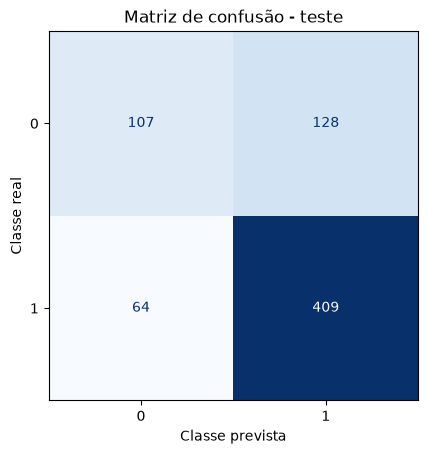

Falsos positivos: 128
Falsos negativos: 64


In [17]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

test_confusion = confusion_matrix(y_test, test_predictions, labels=[0, 1])
ConfusionMatrixDisplay(test_confusion, display_labels=[0, 1]).plot(
    cmap="Blues", colorbar=False,
)
plt.xlabel("Classe prevista")
plt.ylabel("Classe real")
plt.title("Matriz de confusão - teste")
plt.show()

true_negatives, false_positives, false_negatives, true_positives = test_confusion.ravel()
print(f"Falsos positivos: {false_positives}")
print(f"Falsos negativos: {false_negatives}")


### 8.3. Resultados e limitações

Nos 708 registros de teste, houve **516 acertos, 128 falsos positivos e 64 falsos negativos**. O modelo identificou **86,5% da classe 1** e **45,5% da classe 0**, com ROC-AUC de **0,792**, acurácia de **72,9%** e acurácia balanceada de **66,0%**.

Na validação cruzada da seção 7.3, o XGBoost sem ponderação foi selecionado por apresentar a maior ROC-AUC média, embora a diferença em relação à versão ponderada tenha sido pequena. A versão sem pesos identificou uma proporção maior de participantes com burnout elevado, mesmo apresentando uma taxa maior de falsos positivos. Esse resultado é coerente com a prioridade do trabalho de reduzir falsos negativos. Em um contexto de apoio à avaliação profissional, um falso negativo pode reduzir a atenção dada a um caso que merece investigação.

Limitações:

- A classificação representa a condição observada, sem constituir diagnóstico ou previsão de burnout futuro.
- Contexto restrito dos dados. A base foi coletada durante a pandemia, em outros países. Ainda não sabemos se o desempenho seria semelhante no Brasil ou fora daquele contexto.
- Permanecem as limitações dos questionários, das ausências e dos agrupamentos, sem validação em outra população.

## 9. Explicabilidade do modelo

Utilizar SHAP para explicar o comportamento geral do modelo e suas previsões individuais no conjunto de teste.

### 9.1. Cálculo dos valores SHAP

Aplicar as transformações aprendidas no treino e calcular a contribuição de cada atributo para as previsões. Valores SHAP positivos favorecem a classe 1 e negativos a classe 0.

**Observações:**

- As contribuições são expressas em **log-odds**, a escala interna do modelo, e não em pontos percentuais de probabilidade.

- As explicações mostram como o modelo utiliza os atributos, **sem demonstrar relações de causa e efeito** sobre o burnout.

In [18]:
import warnings

import numpy as np

with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="IProgress not found.*")
    import shap

prepare = best_pipeline.named_steps["prepare"]
model = best_pipeline.named_steps["model"]
feature_names = [name.split("__", 1)[-1] for name in prepare.get_feature_names_out()]

X_test_prepared = pd.DataFrame(
    prepare.transform(X_test), columns=feature_names, index=X_test.index,
)

explainer = shap.TreeExplainer(
    model, model_output="raw", feature_perturbation="tree_path_dependent",
)
shap_values = explainer(X_test_prepared)

print(f"Explicações calculadas para {len(X_test_prepared)} registros de teste.")


Explicações calculadas para 708 registros de teste.


### 9.2. Explicação global

O primeiro gráfico (Bar Plot) mostra a importância média dos atributos, sem distinguir contribuições positivas ou negativas. Barras maiores indicam maior influência nas previsões.

Na segunda visualização (Beeswarm), cada ponto representa um participante para aquele atributo. Pontos à direita favorecem a classe 1 e à esquerda a classe 0. A cor indica o valor do atributo: vermelho para valores altos e azul para baixos.

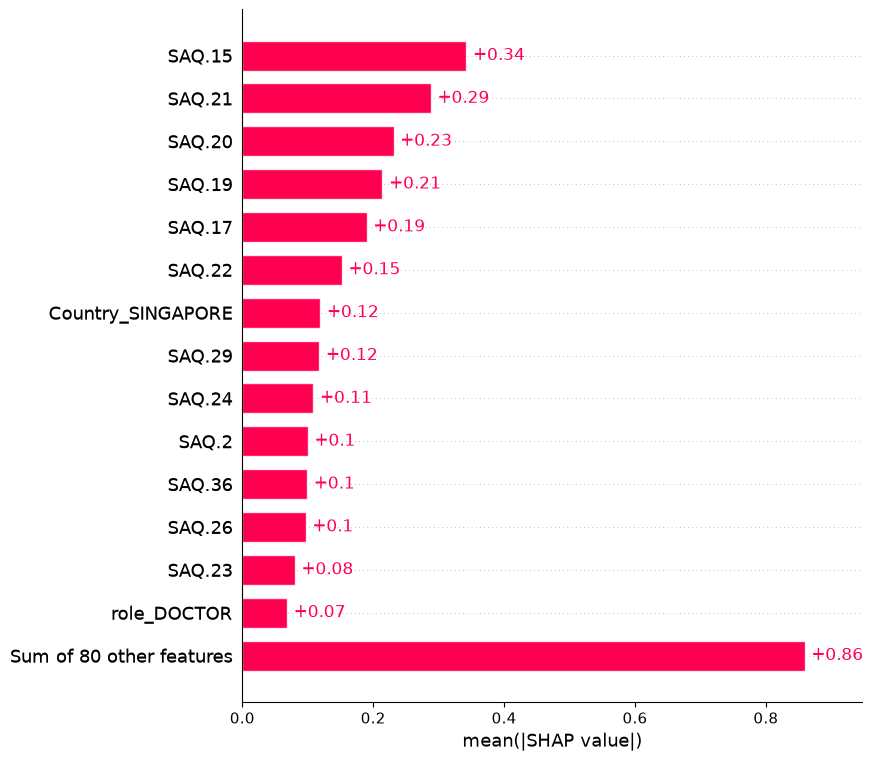

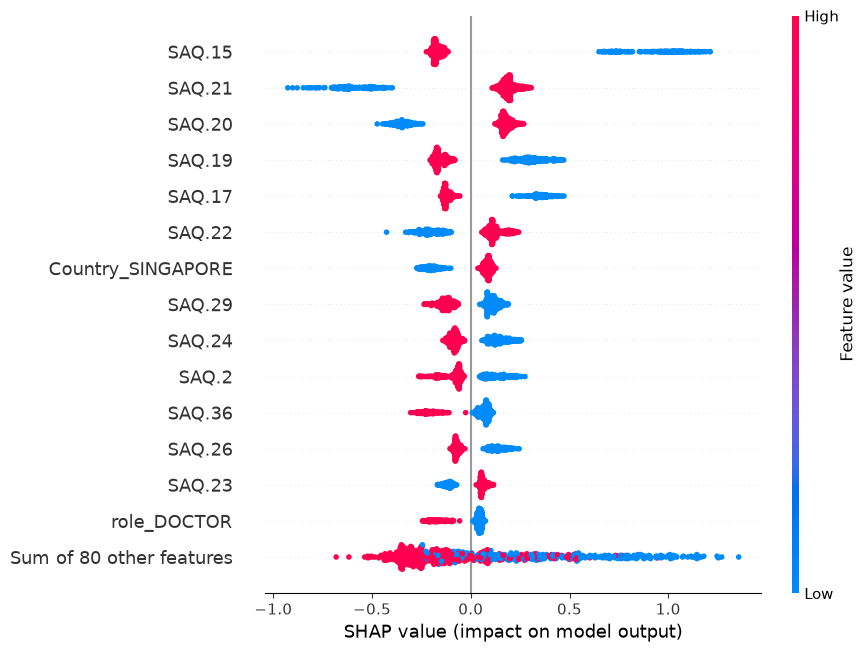

In [19]:
shap.plots.bar(shap_values, max_display=15)
shap.plots.beeswarm(shap_values, max_display=15)


### 9.3. Explicações locais

Analisar o primeiro registro de cada situação no teste:
- Verdadeiro positivo
- Verdadeiro negativo
- Falso positivo
- Falso negativo

O gráfico Waterfall mostra como os atributos contribuem para cada previsão: vermelho favorece a classe 1 e azul, a classe 0. As contribuições estão em log-odds, não em pontos percentuais.

Cada exemplo apresenta também a probabilidade estimada de classe 1.


Verdadeiro positivo | Classe real: 1 | Classe prevista: 1
Probabilidade estimada de classe 1: 94.7%


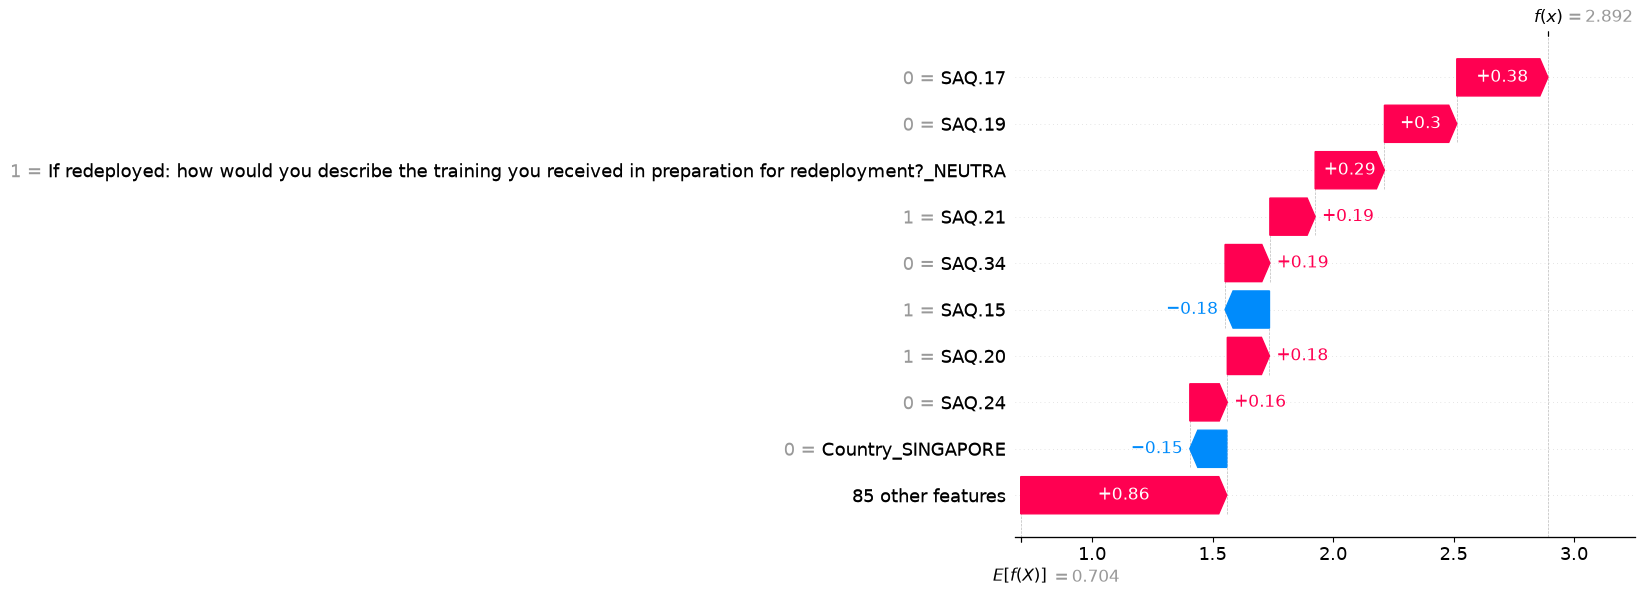

Verdadeiro negativo | Classe real: 0 | Classe prevista: 0
Probabilidade estimada de classe 1: 37.2%


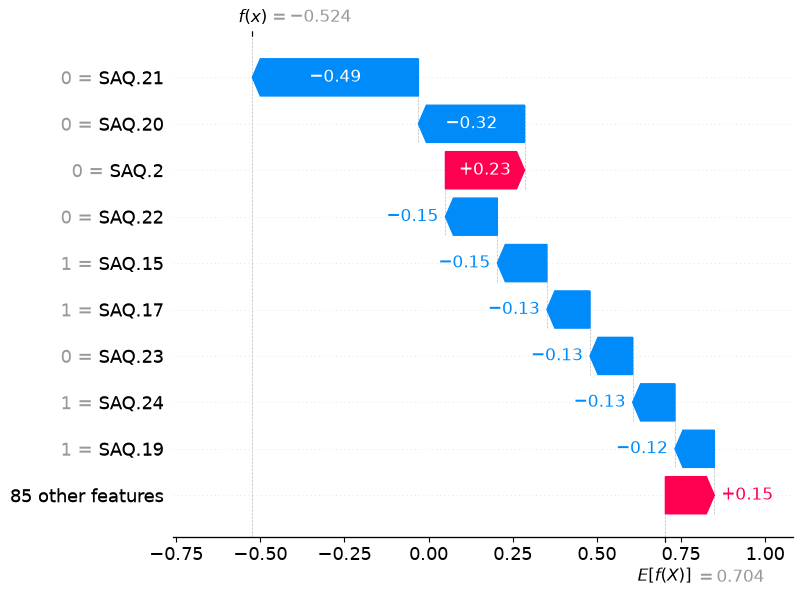

Falso positivo | Classe real: 0 | Classe prevista: 1
Probabilidade estimada de classe 1: 92.8%


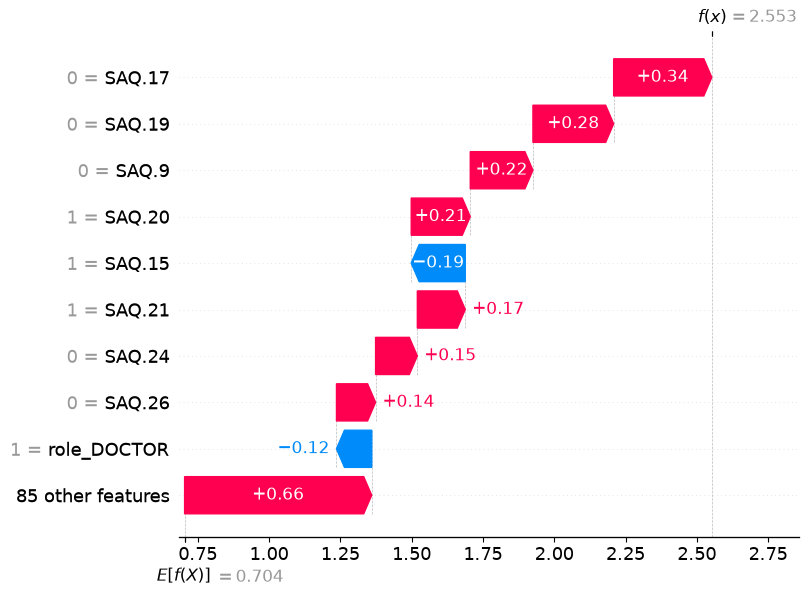

Falso negativo | Classe real: 1 | Classe prevista: 0
Probabilidade estimada de classe 1: 24.1%


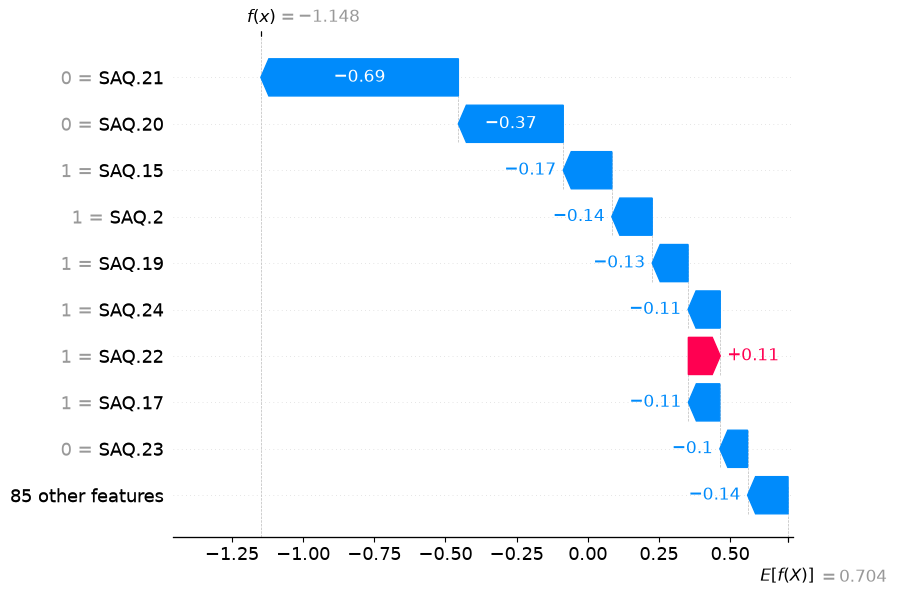

In [20]:
local_cases = {
    "Verdadeiro positivo": (1, 1),
    "Verdadeiro negativo": (0, 0),
    "Falso positivo": (0, 1),
    "Falso negativo": (1, 0),
}

for case, (actual, predicted) in local_cases.items():
    positions = np.flatnonzero(
        y_test.eq(actual).to_numpy() & (test_predictions == predicted)
    )
    if len(positions) == 0:
        print(f"{case}: nenhum registro no teste.")
        continue

    position = int(positions[0])
    print(f"{case} | Classe real: {actual} | Classe prevista: {predicted}")
    print(f"Probabilidade estimada de classe 1: {test_probabilities[position]:.1%}")
    shap.plots.waterfall(shap_values[position], max_display=10)


### 9.4. Discussão das explicações

Os principais atributos foram satisfação com o trabalho (`SAQ.15`), eficácia sob fadiga (`SAQ.21`), sobrecarga (`SAQ.20`), moral da equipe (`SAQ.19`) e ambiente de trabalho (`SAQ.17`). Respostas favoráveis sobre satisfação e ambiente tendem a reduzir a probabilidade estimada de burnout elevado, enquanto concordar com os efeitos da fadiga e da sobrecarga tende a aumentá-la.

Os exemplos mostram que respostas semelhantes podem levar a previsões corretas ou incorretas. O modelo estimou 92,8% para o falso positivo e 24,1% para o falso negativo. Esses erros reforçam que suas previsões devem apoiar a avaliação profissional, sem substituir o julgamento dos responsáveis.

Limitações da interpretação:

- O código 0 reúne neutralidade e discordância. Por exemplo, em “Gosto do meu trabalho”, tanto “Neutro” quanto “Discordo totalmente” recebem 0, embora expressem opiniões diferentes.

- O SHAP explica as previsões, não as causas do burnout. Atributos relacionados podem dividir a importância. 

- O país influencia as previsões, mas isso não significa que cause burnout.

- Os quatro exemplos não representam todos os casos. As explicações ainda não foram avaliadas por profissionais da área.